In [1]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
from scipy.signal import cheby1, filtfilt
import pandas as pd
import matplotlib as mpl

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

import dask
dask.config.set({'array.slicing.split_large_chunks': True})
from scipy import stats

import json
import Plot

In [2]:
def lat_formatter(x, pos):
    hemi = 'N' if x > 0 else 'S' if x < 0 else ''
    return f"{abs(int(x))}°{hemi}"

def lon_formatter(x, pos):
    if x < 180:
        return f"{int(x)}°E"
    elif x == 180:
        return f"{int(x)}°"
    else:
        return f"{int(360-x)}°W"

In [3]:
def get_maxindex(ds):
    # Maximum in the north hemisphere
    imax_nh = np.nanargmax(ds.where(ds.lat>0))
    imax_sh = np.nanargmax(ds.where(ds.lat<0))
    return [imax_sh, imax_nh]

def get_zeroindex(ds):
    # NH: constrain search to 20°N–50°N, find lat index closest to zero
    ds_nh = ds.where((ds.lat > 20) & (ds.lat < 50))
    inh = int(np.abs(ds_nh).argmin("lat"))

    # SH: constrain search to 50°S–20°S, find lat index closest to zero
    ds_sh = ds.where((ds.lat > -50) & (ds.lat < -20))
    ish = int(np.abs(ds_sh).argmin("lat"))

    return [inh, ish]

In [4]:
def absmax_2d(ds):
    max_nh = ds.where(ds['lat']>5).argmax(dim=['lat', 'plev'])
    max_sh = ds.where(ds['lat']<-5).argmin(dim=['lat', 'plev'])
    return [max_nh, max_sh]

def max_value_2d(ds):
    max_nh = ds.where(ds['lat']>0).max(dim=['lat', 'plev'])
    min_sh = ds.where(ds['lat']<0).min(dim=['lat', 'plev'])
    return [max_nh, min_sh]

def max_value(ds):
    max_nh = ds.where(ds['lat']>0).max(dim=['lat'])
    min_sh = ds.where(ds['lat']<0).min(dim=['lat'])
    return [max_nh, min_sh]

In [5]:
ds = xr.open_dataset("Figure11.nc")

In [7]:
max_nh_hist

<xarray.DataArray 'psi_hist' (year_hist: 60)> Size: 480B
array([48.92328142, 51.325323  , 56.11525473, 54.92954009, 53.05257555,
       52.98106069, 51.37603158, 55.98895904, 56.89510533, 57.28529252,
       59.2276751 , 66.50637627, 63.55559039, 58.11577492, 60.92771575,
       60.4544936 , 64.21655683, 59.7065725 , 60.03685849, 59.1313816 ,
       55.78646877, 65.4075181 , 69.74191878, 59.0959998 , 62.09504621,
       62.84989606, 70.86093303, 58.12983568, 62.8394733 , 62.84498353,
       67.73321175, 65.44321293, 63.15873572, 66.5413955 , 67.28622052,
       63.07667392, 63.88302771, 66.28796906, 58.5099084 , 67.13337009,
       60.47064821, 65.55416163, 64.99920767, 66.41694355, 65.94860591,
       65.28355302, 61.54863014, 63.33585861, 64.25346433, 65.78836795,
       63.84370775, 63.41739154, 58.02570254, 60.82498153, 64.98876011,
       63.05559424, 54.70172238, 56.77662983, 55.60165861, 57.81795091])
Coordinates:
  * year_hist  (year_hist) int64 480B 1961 1962 1963 1964 ... 2018 2019 2020
    plev       float64 8B 500.0

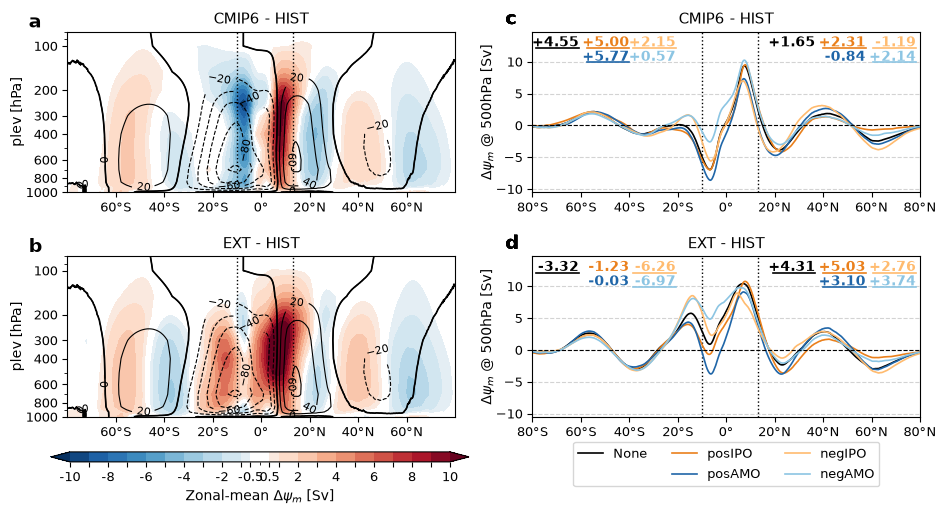

In [9]:
fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(11,5))
plt.subplots_adjust(hspace=0.4, wspace=0.2)
lat_range = slice(-80, 80)
ratio = 100
numbers = [['a', 'c'], ['b', 'd']]
titles = [['CMIP6 - HIST', 'CMIP6 - HIST'], ['EXT - HIST', 'EXT - HIST']]
trends = ['CMIP6', 'Hadley']
internals = ['noIPO', 'posIPO', 'posAMO', 'negIPO', 'negAMO']
colors = {
    'posIPO':'#ea801c', 'negIPO':'#ffbb6f', 
    'noIPO':'k', 
    'posAMO':'#2066a8', 'negAMO':'#8cc5e3',
}
cmap1, levels1, norm1 = Plot.def_colormap(max=10, white=0.5, interval=1, cmap='RdBu_r')

# Column 1: historical overtunning circulation
for irow in range(2):
    ds_now_l1 = ds[f'psi_{trends[irow]}_noIPO'].mean('year_futu')
    ds_now_l2 = ds.psi_hist.mean('year_hist')
    cf = axs[irow][0].contourf(ds_now_l1.lat, ds_now_l1.plev, ds_now_l1 - ds_now_l2, 
                               cmap=cmap1, levels=levels1, norm=norm1, extend='both')
    cc = axs[irow][0].contour(ds_now_l2.lat, ds_now_l2.plev, ds_now_l2, 
                              levels=np.arange(-200, 200+20, 20), colors='black', linewidths=0.8)
    axs[irow][0].contour(ds_now_l2.lat, ds_now_l2.plev, ds_now_l2, 
                              levels=[0], colors='black', linewidths=1.2)
    axs[irow][0].clabel(cc, inline=True, fontsize=8)
    axs[irow][0].set_title(titles[irow][0], fontsize=11)
    axs[irow][0].annotate(
        numbers[irow][0], xy=(-0.1, 1.12), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
    )

hist = ds.psi_hist.mean('year_hist')
nh_hist, sh_hist = max_value(hist.sel(plev=500))
max_nh_hist, min_sh_hist = max_value(ds.psi_hist.sel(plev=500))

# Column 2: vertical average stream function relative to Hist
text_position={
    'posIPO':[(0.87-0.62, 0.91), (0.86, 0.91)], 'posAMO':[(0.87-0.62, 0.82), (0.86, 0.82)], 
    'noIPO':[(0.74-0.62, 0.91), (0.73, 0.91)], 
    'negIPO':[(0.99-0.62, 0.91), (0.99, 0.91)], 'negAMO':[(0.99-0.62, 0.82), (0.99, 0.82)],
}
p_sh={'CMIP6-noIPO':True, 'CMIP6-posIPO':True, 'CMIP6-negIPO':True, 
                          'CMIP6-posAMO':True,'CMIP6-negAMO':True,
      'Hadley-noIPO':True, 'Hadley-posIPO':True, 'Hadley-negIPO':True, 
                           'Hadley-posAMO':True, 'Hadley-negAMO':True,}
p_nh={'CMIP6-noIPO':True, 'CMIP6-posIPO':True, 'CMIP6-negIPO':True, 
                          'CMIP6-posAMO':True,'CMIP6-negAMO':True,
      'Hadley-noIPO':True, 'Hadley-posIPO':True, 'Hadley-negIPO':True, 
                           'Hadley-posAMO':True, 'Hadley-negAMO':True,}

for irow in range(2):
    for jj, iinternal in enumerate(internals):
        ds_now = ds[f'psi_{trends[irow]}_{iinternal}'].mean('year_futu')
        nh, sh = absmax_2d(ds_now)
        nhedge, shedge = get_zeroindex(ds_now.sel(plev=500))
        nh_values, sh_values = max_value(ds_now.sel(plev=500))
        max_nh_futu, min_sh_futu = max_value(ds[f'psi_{trends[irow]}_{iinternal}'].sel(plev=500))
        _, p_nh = stats.ttest_ind(max_nh_hist.values.flatten(), max_nh_futu.values.flatten(), equal_var=False)
        _, p_sh = stats.ttest_ind(min_sh_hist.values.flatten(), min_sh_futu.values.flatten(), equal_var=False)
        
        ds_now_l1 = ds_now.sel(plev=500)
        ds_now_l2 = ds.psi_hist.sel(plev=500).mean('year_hist')
        (ds_now_l1-ds_now_l2).plot(ax=axs[irow][1], color=colors[iinternal], linestyle='solid', linewidth=1.2,
                                   label=iinternal if iinternal!='noIPO' else 'None')
        if iinternal == 'noIPO':
            axs[irow][0].axvline(ds_now['lat'][nh['lat']], color=colors[iinternal], linestyle='dotted', linewidth=1,)
            axs[irow][0].axvline(ds_now['lat'][sh['lat']], color=colors[iinternal], linestyle='dotted', linewidth=1,)
            axs[irow][1].axvline(ds_now['lat'][nh['lat']], color=colors[iinternal], linestyle='dotted', linewidth=1,)
            axs[irow][1].axvline(ds_now['lat'][sh['lat']], color=colors[iinternal], linestyle='dotted', linewidth=1,)

        axs[irow][1].annotate(f'{-(sh_values-sh_hist):+.2f}', text_position[iinternal][0], ha='right',
                              xycoords='axes fraction', color=colors[iinternal], weight='semibold')
        axs[irow][1].annotate(f'{(nh_values-nh_hist):+.2f}', text_position[iinternal][1], ha='right',
                              xycoords='axes fraction', color=colors[iinternal], weight='semibold')
        if p_sh: 
            axs[irow][1].plot([text_position[iinternal][0][0]-0.11, text_position[iinternal][0][0]-0.11+0.11], 
                              [text_position[iinternal][0][1]-0.01, text_position[iinternal][0][1]-0.01], 
                              transform=axs[irow][1].transAxes, color=colors[iinternal], lw=1.2, clip_on=False)
        if p_nh: 
            axs[irow][1].plot([text_position[iinternal][1][0]-0.11, text_position[iinternal][1][0]-0.11+0.11], 
                              [text_position[iinternal][1][1]-0.01, text_position[iinternal][1][1]-0.01], 
                              transform=axs[irow][1].transAxes, color=colors[iinternal], lw=1.2, clip_on=False)
        
        axs[irow][1].set_title(titles[irow][1], fontsize=11)
        axs[irow][1].annotate(
            numbers[irow][1], xy=(-0.07, 1.14), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
        )
    
for ax in axs[:,0]:
    ax.invert_yaxis()
    ax.set_yscale('log')
    ax.set_ylim(1000, 80)
    ax.tick_params(labelsize=9)
    ax.set_yticks([100, 200, 300, 400, 600, 800, 1000])
    ax.get_yaxis().set_major_formatter(ScalarFormatter())
    ax.set_ylabel('plev [hPa]', labelpad=1)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lat_formatter))
for ax in axs[:,1]:
    ax.grid(axis='y', linewidth=0.8, color='lightgrey', linestyle='dashed')
    ax.axhline(0, linewidth=0.8, linestyle='dashed', color='k')
    ax.set_xlabel('')
    ax.set_ylim(-10.5, 14.7)
    # ax.set_yticks([-6, -3, 0, 3, 6])
    ax.set_xlim(-80, 80)
    ax.tick_params(labelsize=9)
    ax.set_ylabel(r'$\Delta\psi_m$ @ 500hPa [Sv]', labelpad=0.6)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lat_formatter))

handles, labels = axs[1][1].get_legend_handles_labels()
empty = Line2D([], [], color='none', label='')
idx = labels.index('None') + 1
handles.insert(idx, empty)
labels.insert(idx, '')
leg = axs[1][1].legend(
    handles, labels, ncol=3,
    loc='lower center', bbox_to_anchor=(0.5, -0.47), fontsize=9, frameon=True)

cax = fig.add_axes([0.11, 0.02, 0.38, 0.02])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap1, norm=norm1), 
                    cax=cax, orientation='horizontal', ticks=levels1[levels1 != 0], extend='both', spacing='proportional', 
                    label=r'Zonal-mean $\Delta\psi_m$ [Sv]')

major_ticks = [-10, -8, -6, -4, -2, -0.5, 0.5, 2, 4, 6, 8, 10]
major_labels = [
    '' if t not in major_ticks else f'{t:g}'
    for t in levels1[levels1 != 0]
]
cbar.ax.set_xticklabels(major_labels);
cbar.ax.tick_params(labelsize=9)

# plt.savefig(f'Figure11.png', bbox_inches='tight', dpi=300)